In [35]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully.")


Libraries imported successfully.


In [36]:

file_path = r"D:\personal projects\humanVsComputerGeneration\Data\engineered_features.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())


Dataset shape: (5848, 48)

Columns:
['unique_count', 'repeat_count', 'unique_ratio', 'max_frequency', 'single_occurrence_count', 'repeated_value_count', 'mean', 'median', 'std', 'minimum', 'maximum', 'value_range', 'adjacent_repeat_count', 'longest_repeat_run', 'mean_adjacent_difference', 'std_adjacent_difference', 'max_adjacent_difference', 'ascending_pairs', 'descending_pairs', 'increasing_pairs', 'decreasing_pairs', 'small_gap_pairs', 'longest_increasing_run', 'longest_decreasing_run', 'direction_changes', 'entropy', 'odd_count', 'even_count', 'parity_changes', 'lower_range_count', 'upper_range_count', 'gap_unique_count', 'gap_repeat_count', 'max_gap_frequency', 'distinct_adjacent_pairs', 'local_peaks', 'local_valleys', 'count_1', 'count_2', 'count_3', 'count_4', 'count_5', 'count_6', 'count_7', 'count_8', 'count_9', 'count_10', 'label']


,unique_count,repeat_count,unique_ratio,max_frequency,single_occurrence_count,repeated_value_count,mean,median,std,minimum,...,count_2,count_3,count_4,count_5,count_6,count_7,count_8,count_9,count_10,label
0,7,3,0.7,2,4,3,5.6,5.5,2.653300,2,...,2,1,1,1,1,0,2,2,0,0
1,9,1,0.9,2,8,1,4.7,4.5,2.609598,1,...,2,1,1,1,1,1,1,1,0,1
2,6,4,0.6,3,3,3,5.7,5.0,2.410394,1,...,0,0,2,3,0,1,1,2,0,0
3,9,1,0.9,2,8,1,4.6,4.5,2.727636,1,...,1,1,1,1,1,1,1,1,0,1
4,8,2,0.8,2,6,2,5.4,6.0,2.497999,1,...,1,1,0,1,2,2,1,1,0,1


In [37]:

# Check the original labels before remapping
print("Original label counts:")
print(df["label"].value_counts().sort_index())

# Original CSV mapping:
# 0 = Computer, 1 = Human
# Desired mapping:
# 0 = Human, 1 = Computer

df["label"] = df["label"].map({0: 1, 1: 0})

print("\nUpdated label counts:")
print(df["label"].value_counts().sort_index())

print("\nClass proportions:")
print(df["label"].value_counts(normalize=True).sort_index().round(4))


Original label counts:
label
0    5000
1     848
Name: count, dtype: int64

Updated label counts:
label
0     848
1    5000
Name: count, dtype: int64

Class proportions:
label
0    0.145
1    0.855
Name: proportion, dtype: float64


In [38]:

# Separate features and target
X = df.drop(columns=["label"])
y = df["label"]

# Keep numeric features
X = X.select_dtypes(include="number")

# Basic validation
assert X.shape[0] == y.shape[0], "Feature and target row counts differ."
assert y.notna().all(), "Target contains missing values."
assert X.notna().all().all(), "Features contain missing values."

print("Feature matrix:", X.shape)
print("\nTarget distribution:")
print(y.value_counts().sort_index())

print("\nMissing feature values:", X.isna().sum().sum())
print("Missing target values:", y.isna().sum())


Feature matrix: (5848, 47)

Target distribution:
label
0     848
1    5000
Name: count, dtype: int64

Missing feature values: 0
Missing target values: 0


In [39]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining label counts:")
print(y_train.value_counts().sort_index())

print("\nTesting label counts:")
print(y_test.value_counts().sort_index())


Training features: (4678, 47)
Testing features: (1170, 47)

Training label counts:
label
0     678
1    4000
Name: count, dtype: int64

Testing label counts:
label
0     170
1    1000
Name: count, dtype: int64


In [40]:

rf_baseline = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_baseline.fit(X_train, y_train)

print("Baseline Random Forest trained.")


Baseline Random Forest trained.



Baseline Random Forest
              precision    recall  f1-score   support

       Human       0.85      0.59      0.70       170
    Computer       0.93      0.98      0.96      1000

    accuracy                           0.93      1170
   macro avg       0.89      0.79      0.83      1170
weighted avg       0.92      0.93      0.92      1170



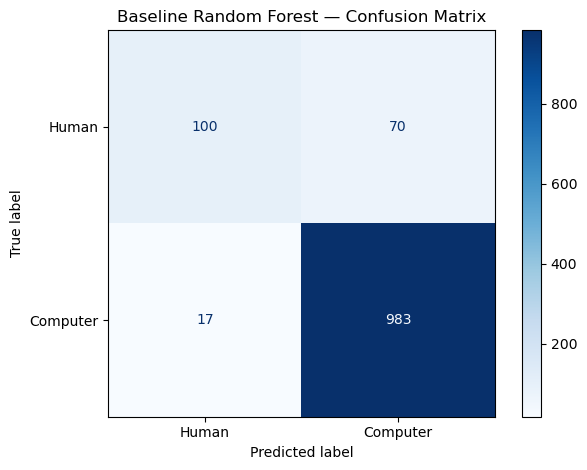

,Accuracy,Human Precision,Human Recall,Human F1,Computer Precision,Computer Recall,Computer F1,ROC-AUC
Model,,,,,,,,
Baseline Random Forest,0.9256,0.8547,0.5882,0.6969,0.9335,0.983,0.9576,0.9382


In [41]:

def evaluate_model(model, X_test, y_test, model_name):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Human Precision": precision_score(
            y_test, predictions, pos_label=0, zero_division=0
        ),
        "Human Recall": recall_score(
            y_test, predictions, pos_label=0, zero_division=0
        ),
        "Human F1": f1_score(
            y_test, predictions, pos_label=0, zero_division=0
        ),
        "Computer Precision": precision_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "Computer Recall": recall_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "Computer F1": f1_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

    print(f"\n{model_name}")
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["Human", "Computer"],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=["Human", "Computer"],
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"{model_name} — Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return metrics


baseline_results = evaluate_model(
    rf_baseline,
    X_test,
    y_test,
    "Baseline Random Forest"
)

display(pd.DataFrame([baseline_results]).set_index("Model").round(4))


In [42]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, f1_score

# Optimize F1-score for the human-generated class (label = 0)
human_f1_scorer = make_scorer(f1_score, pos_label=0)

# Define the hyperparameter search space
param_distributions = {
    "n_estimators": [200, 300, 400, 500],
    "max_depth": [10, 15, 20, 25, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2"],
    "class_weight": ["balanced", "balanced_subsample", None]
}

# Use stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Initialize the Random Forest
rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Search 40 random hyperparameter combinations
rf_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions,
    n_iter=40,
    scoring=human_f1_scorer,
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    return_train_score=True
)

# Fit using training data only
rf_search.fit(X_train, y_train)

# Display the best results
print("Best cross-validation Human F1-score:")
print(round(rf_search.best_score_, 4))

print("\nBest hyperparameters:")
print(rf_search.best_params_)

# Store the best estimator
tuned_rf = rf_search.best_estimator_


Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best cross-validation Human F1-score:
0.6864

Best hyperparameters:
{'n_estimators': 500, 'min_samples_split': 20, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': None, 'class_weight': 'balanced'}


In [43]:

rf_tuned = RandomForestClassifier(
    n_estimators=300,
    min_samples_split=20,
    min_samples_leaf=1,
    max_features="sqrt",
    max_depth=20,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_tuned.fit(X_train, y_train)

print("Tuned Random Forest trained.")


Tuned Random Forest trained.



Tuned Random Forest
              precision    recall  f1-score   support

       Human       0.66      0.69      0.68       170
    Computer       0.95      0.94      0.94      1000

    accuracy                           0.90      1170
   macro avg       0.81      0.81      0.81      1170
weighted avg       0.91      0.90      0.90      1170



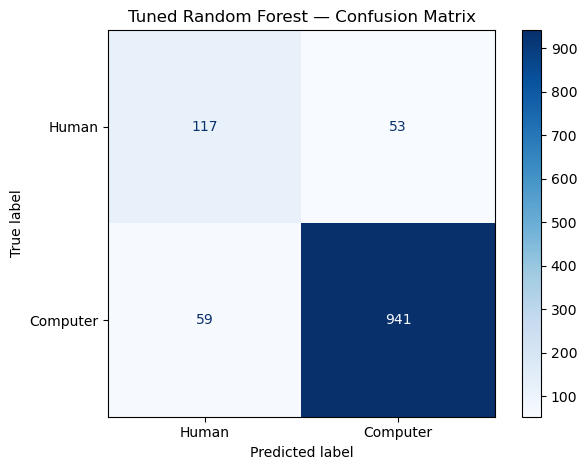

,Accuracy,Human Precision,Human Recall,Human F1,Computer Precision,Computer Recall,Computer F1,ROC-AUC
Model,,,,,,,,
Tuned Random Forest,0.9043,0.6648,0.6882,0.6763,0.9467,0.941,0.9438,0.9431


In [44]:

tuned_results = evaluate_model(
    rf_tuned,
    X_test,
    y_test,
    "Tuned Random Forest"
)

display(pd.DataFrame([tuned_results]).set_index("Model").round(4))


In [45]:

comparison = pd.DataFrame([
    baseline_results,
    tuned_results
]).set_index("Model")

display(comparison.T.round(4))


Model,Baseline Random Forest,Tuned Random Forest
Accuracy,0.9256,0.9043
Human Precision,0.8547,0.6648
Human Recall,0.5882,0.6882
Human F1,0.6969,0.6763
Computer Precision,0.9335,0.9467
Computer Recall,0.9830,0.9410
Computer F1,0.9576,0.9438
ROC-AUC,0.9382,0.9431


Top 20 features:


,Feature,Importance
0,unique_count,0.098016
1,unique_ratio,0.094909
2,entropy,0.094867
3,repeat_count,0.087489
4,single_occurrence_count,0.064374
5,longest_repeat_run,0.044604
6,adjacent_repeat_count,0.040915
7,max_frequency,0.040031
8,count_5,0.030312
9,std,0.028416


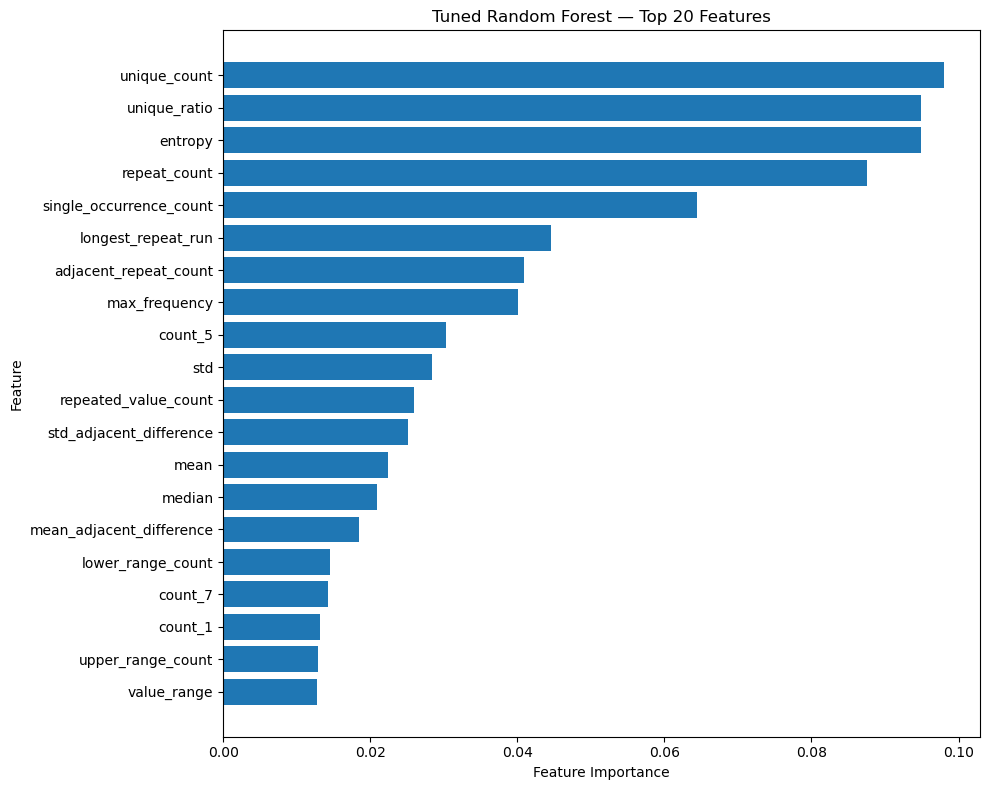

In [46]:

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_tuned.feature_importances_
}).sort_values("Importance", ascending=False)

print("Top 20 features:")
display(feature_importance.head(20).reset_index(drop=True))

top_features = feature_importance.head(20).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 8))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Tuned Random Forest — Top 20 Features")
plt.tight_layout()
plt.show()


In [47]:

import joblib
from pathlib import Path

model_path = Path(
    r"D:\personal projects\humanVsComputerGeneration"
    r"\Models\random_forest_tuned.joblib"
)

model_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(rf_tuned, model_path)

print(f"Model saved to: {model_path}")


Model saved to: D:\personal projects\humanVsComputerGeneration\Models\random_forest_tuned.joblib
